# Learning the Au–CO₂⁺ potential energy surface from DFT calculations

I wanted to see whether I could reproduce my calculated Au–CO₂⁺ potential energy surface using fewer DFT points. I used a Gaussian Process to predict energies from Au–C distance and angle, then compared different ways of choosing the training points.

The calculations use UB3P86/def2-TZVP. The C–O distances are fixed, so this is a scan of two coordinates rather than the complete molecular potential energy surface.


## 1. Load the data

Find the Gaussian output files from my Au–CO₂⁺ scans.


In [15]:
from pathlib import Path
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from sklearn.exceptions import ConvergenceWarning

HARTREE_TO_EV = 27.211386245988
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})

notebook_folder = Path.cwd()
scan_folder = notebook_folder / "Au_CO2_Scans"

log_files = sorted(scan_folder.rglob("Au_CO2_Scan_D2_*.log"))
print(f"Found {len(log_files)} scan files")

Found 26 scan files


## 2. Extract the energies

Each file contains a preliminary calculation followed by a scan from 0° to 90°. I extract the 91 scan energies and check that each file completed normally.


In [16]:
rows = []

for path in log_files:
    match = re.search(r"D2_(\d+\.\d+)", path.name)
    radius = float(match.group(1))
    text = path.read_text(errors="replace")

    scan_text = text.split("Scan the potential surface.", 1)[1]
    matches = re.findall(
        r"SCF Done:\s+E\([^)]+\)\s*=\s*(-?\d+\.\d+(?:[DEde][+-]?\d+)?)",
        scan_text
    )
    
    energies = [float(value.replace("D", "E").replace("d", "e")) for value in matches]

    for angle, energy in enumerate(energies):
        rows.append((radius, angle, energy))

df = pd.DataFrame(rows, columns=["radius", "angle", "energy_hartree"])
df = df.sort_values(["radius", "angle"]).reset_index(drop=True)

# A common energy zero is useful for plotting and model comparison.
reference_hartree = df["energy_hartree"].min()
df["energy_ev"] = (df["energy_hartree"] - reference_hartree) * HARTREE_TO_EV
print(df.shape, "| radii:", df.radius.nunique(), "| angles:", df.angle.nunique())
display(df.head())

(2366, 4) | radii: 26 | angles: 91


,radius,angle,energy_hartree,energy_ev
0,2.5,0,-324.413293,13.549534
1,2.5,1,-324.414124,13.526933
2,2.5,2,-324.416606,13.459389
3,2.5,3,-324.420712,13.347663
4,2.5,4,-324.426396,13.192987


## 3. Plot the DFT energy surface

This is a clear way to show the landscape around CO₂. I reflect the 0–90° scan to make a full circle, assuming the expected symmetry. The white inner region is hidden for clarity, and the highest energies share the same colour. Neither change affects the data used later.

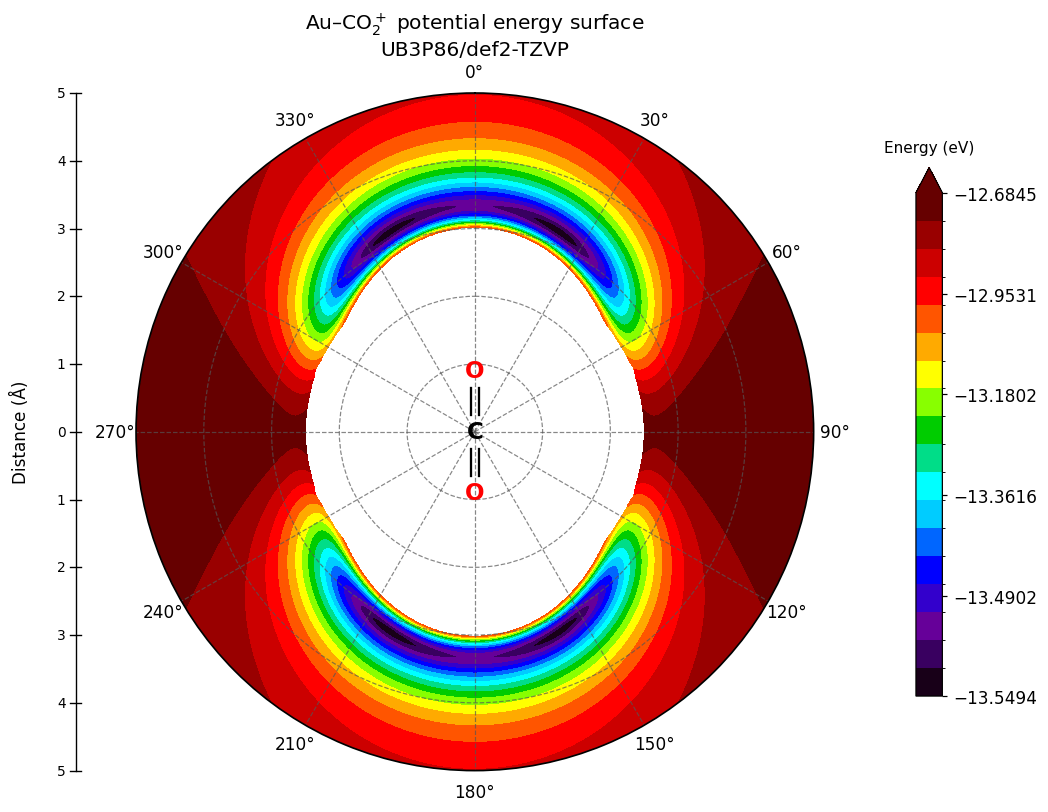

In [17]:
grid = df.pivot(index="angle", columns="radius", values="energy_ev").sort_index().sort_index(axis=1)

# Energy reference for this figure: highest sampled DFT energy = 0 eV
# Use the highest calculated energy as zero for this plot.
plot_grid = grid - grid.values.max()
a = plot_grid.index.to_numpy(float)
r = plot_grid.columns.to_numpy(float)
interpolator = RegularGridInterpolator((a, r), plot_grid.values, method="cubic")
angle_plot = np.linspace(0, 360, 721)
r_plot = np.linspace(r.min(), r.max(), 501)
folded = np.degrees(np.arccos(np.clip(np.abs(np.cos(np.deg2rad(angle_plot))), 0, 1)))
AA, RR = np.meshgrid(folded, r_plot, indexing="ij")
E = interpolator(np.column_stack([AA.ravel(), RR.ravel()])).reshape(AA.shape)
TH, R = np.meshgrid(np.deg2rad(angle_plot), r_plot, indexing="ij")

# Hide the high-energy inner region while keeping the low-energy pockets.
boundary_energy = -13.0
inner = np.full(len(angle_plot), r.min())
for i, profile in enumerate(E):
    hits = np.flatnonzero(profile <= boundary_energy)
    if len(hits):
        inner[i] = r_plot[hits[0]]
inner = gaussian_filter1d(inner, sigma=3, mode="wrap")
E_show = np.ma.masked_where(R < inner[:, None], E)

palette = ["#180018", "#390060", "#660099", "#3300CC", "#0000FF",
           "#0066FF", "#00CCFF", "#00FFFF", "#00DD88", "#00CC00",
           "#88FF00", "#FFFF00", "#FFAA00", "#FF5500", "#FF0000",
           "#CC0000", "#990000", "#660000"]
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(palette)
cmap.set_bad("white")
cmap.set_over("#660000")
lo = float(E_show.min())
hi = min(float(E_show.max()), -11.5)
# Spread the colours out more around the low-energy part of the surface.
gamma = 0.6
levels = lo + (hi - lo) * np.linspace(0, 1, len(palette) + 1)**(1/gamma)

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_ylim(0, 5)
ax.set_thetagrids(np.arange(0, 360, 30))
ax.set_rticks(np.arange(1, 6))
ax.set_yticklabels([])
cs = ax.contourf(TH, R, E_show, levels=levels, cmap=cmap,
                 norm=BoundaryNorm(levels, cmap.N), extend="max")
ax.grid(color="#555555", linestyle="--", linewidth=0.8, alpha=0.7)
ax.spines["polar"].set_linewidth(1.1)

# Small central sketch (not to scale)
x0 = 0.5
for y1, y2 in [(0.525, 0.565), (0.435, 0.475)]:
    for dx in (-0.006, 0.006):
        ax.plot([x0 + dx, x0 + dx], [y1, y2], transform=ax.transAxes,
                color="black", linewidth=1.5, zorder=10)
for yy, atom, colour in [(0.59, "O", "red"), (0.5, "C", "black"), (0.41, "O", "red")]:
    ax.text(x0, yy, atom, color=colour, ha="center", va="center",
            transform=ax.transAxes, fontsize=15, fontweight="bold", zorder=11)

cb = fig.colorbar(cs, ax=ax, fraction=0.045, pad=0.12, shrink=0.78, spacing="uniform")
cb.set_ticks(lo + (hi-lo)*np.linspace(0, 1, 6)**(1/gamma))
cb.ax.set_title("Energy (eV)", fontsize=10, pad=10)
ax.set_title("Au–CO$_2^+$ potential energy surface\nUB3P86/def2-TZVP", pad=25)

# Draw an external vertical distance scale after the colourbar is placed.
from matplotlib.lines import Line2D
fig.canvas.draw()
to_fig = ax.transData + fig.transFigure.inverted()
top = to_fig.transform((0, 5))
bottom = to_fig.transform((np.pi, 5))
left = to_fig.transform((3*np.pi/2, 5))
centre = to_fig.transform((0, 0))
axis_x = left[0] - 0.055
fig.add_artist(Line2D([axis_x, axis_x], [bottom[1], top[1]],
                      transform=fig.transFigure, color="black", linewidth=0.9))
for signed_r in range(-5, 6):
    angle_here = 0 if signed_r >= 0 else np.pi
    y_fig = to_fig.transform((angle_here, abs(signed_r)))[1]
    fig.add_artist(Line2D([axis_x-0.005, axis_x+0.005], [y_fig, y_fig],
                          transform=fig.transFigure, color="black", linewidth=0.9))
    fig.text(axis_x-0.009, y_fig, str(abs(signed_r)), ha="right", va="center", fontsize=9)
fig.text(axis_x-0.05, centre[1], "Distance (Å)", rotation=90, ha="center", va="center")
plt.show()

## 4. Fit a Gaussian Process

The model uses Au–C distance and angle to predict the DFT energy. I keep some calculations aside to test how well it predicts points it has not been trained on.

Because the test points lie within the same scan, this mainly tests interpolation between known geometries.


In [18]:
X = df[["radius", "angle"]].to_numpy()
y = df["energy_ev"].to_numpy()
all_idx = np.arange(len(df))
pool_idx, test_idx = train_test_split(all_idx, test_size=0.20, random_state=42)

# Keep the test geometries fixed for every sampling strategy.
print(f"Candidate pool: {len(pool_idx)} | Held-out test points: {len(test_idx)}")

# Use the same fitting settings for each selection method.
def fit_gp(indices):
    scale = StandardScaler()
    x_fit = scale.fit_transform(X[indices])
    kernel = ConstantKernel(1.0, (1e-3, 1e6)) * Matern(
        length_scale=[1.0, 1.0], length_scale_bounds=(1e-2, 1e3), nu=2.5
    )
    model = GaussianProcessRegressor(
        kernel=kernel, alpha=1e-5, normalize_y=True,
        n_restarts_optimizer=1, random_state=42
    )
    
    model.fit(x_fit, y[indices])
    return model, scale

def test_metrics(model, scale):
    pred = model.predict(scale.transform(X[test_idx]))
    err = pred - y[test_idx]
    return (np.sqrt(np.mean(err**2)), np.mean(np.abs(err)), np.max(np.abs(err)))

initial_idx = np.random.default_rng(42).choice(pool_idx, size=47, replace=False)
model, scale = fit_gp(initial_idx)
print("Kernel:", model.kernel_)
print("RMSE, MAE, max error (eV):", test_metrics(model, scale))

Candidate pool: 1892 | Held-out test points: 474
Kernel: 8.03**2 * Matern(length_scale=[1.48, 4.76], nu=2.5)
RMSE, MAE, max error (eV): (np.float64(0.5467962225388023), np.float64(0.17823316497026787), np.float64(4.780380949360632))


## 5. Choose the training points

I compare three approaches:

- Random: choose points at random.
- Uncertainty: choose points where the model is least confident.
- Diversity-aware: choose uncertain points, but also try to avoid selecting points too close together.

All three methods use the same starting points and test data. The test energies are not used to choose new training points.


In [19]:
def choose_diverse(model, scale, chosen, available, n_add, weight=0.5):
    xc = scale.transform(X[available])
    xs = scale.transform(X[chosen])
    _, uncertainty = model.predict(xc, return_std=True)
    uncertainty = uncertainty / max(uncertainty.max(), 1e-12)
    distances = cdist(xc, xs).min(axis=1)
    eligible = np.ones(len(available), dtype=bool)
    picks = []

    # After each choice, update the distance to the nearest selected point.
    for _ in range(n_add):
        diversity = distances / max(distances[eligible].max(), 1e-12)
        score = uncertainty + weight * diversity
        score[~eligible] = -np.inf
        j = int(np.argmax(score))
        picks.append(j)
        eligible[j] = False
        distances = np.minimum(distances, cdist(xc, xc[j:j+1]).ravel())

    return available[picks]


def run_strategy(seed, method, sizes=(47, 118, 237, 473)):
    rng = np.random.default_rng(seed)
    chosen = rng.choice(pool_idx, size=sizes[0], replace=False)
    records = []
    chosen_by_size = {}
    previous_model = previous_scale = None

    for size in sizes:
        n_add = size - len(chosen)
        if n_add:
            available = np.setdiff1d(pool_idx, chosen)
            if method == "Random":
                new = rng.choice(available, size=n_add, replace=False)
            elif method == "Uncertainty":
                _, sd = previous_model.predict(previous_scale.transform(X[available]), return_std=True)
                new = available[np.argsort(sd)[-n_add:]]
            else:
                new = choose_diverse(previous_model, previous_scale, chosen, available, n_add)
            chosen = np.concatenate([chosen, new])

        model, scale = fit_gp(chosen)
        rmse, mae, max_error = test_metrics(model, scale)
        pred_all = model.predict(scale.transform(X))
        gp_min = np.argmin(pred_all)
        dft_min = np.argmin(y)
        records.append({
            "seed": seed, "method": method, "n_train": size,
            "rmse_ev": rmse, "mae_ev": mae, "max_error_ev": max_error,
            "gp_radius": X[gp_min, 0], "gp_angle": X[gp_min, 1],
            "correct_minimum": bool(gp_min == dft_min),
            "error_at_dft_min_mev": 1000 * (pred_all[dft_min] - y[dft_min])
        })
        chosen_by_size[size] = chosen.copy()
        previous_model, previous_scale = model, scale

    return records, chosen_by_size

## 6. Compare the methods

I repeat the comparison with three different starting sets to see how much the results depend on the initial points.


In [20]:
seeds = [10, 20, 30]
methods = ["Random", "Uncertainty", "Diversity-aware"]
sizes = [47, 118, 237, 473]

records = []
selected_points = {}
t0 = time.time()
# Some fits reach the optimisation bounds. Keep the output focused on the comparison.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for seed in seeds:
        for method in methods:
            print(f"Seed {seed}: {method}")
            part, selections = run_strategy(seed, method, sizes)
            records.extend(part)
            selected_points[(seed, method)] = selections

results = pd.DataFrame(records)
print(f"Completed in {(time.time()-t0)/60:.1f} minutes")
display(results.head())

Seed 10: Random
Seed 10: Uncertainty
Seed 10: Diversity-aware
Seed 20: Random
Seed 20: Uncertainty
Seed 20: Diversity-aware
Seed 30: Random
Seed 30: Uncertainty
Seed 30: Diversity-aware
Completed in 1.8 minutes


,seed,method,n_train,rmse_ev,mae_ev,max_error_ev,gp_radius,gp_angle,correct_minimum,error_at_dft_min_mev
0,10,Random,47,0.573903,0.117858,6.228721,3.4,10.0,False,39.723251
1,10,Random,118,0.173049,0.037285,2.089566,3.3,0.0,False,1.813012
2,10,Random,237,0.060947,0.008067,0.818245,3.2,23.0,True,0.126650
3,10,Random,473,0.005687,0.001174,0.081120,3.2,23.0,True,0.104347
4,10,Uncertainty,47,0.573903,0.117858,6.228721,3.4,10.0,False,39.723251


## 7. Prediction errors and the minimum

I compare the average prediction error and check whether each model finds the same lowest-energy point as DFT. A low average error does not always mean the minimum is in the right location.


,method,n_train,mean_rmse,std_rmse,minima_found
0,Diversity-aware,47,0.660526,0.462850,0
1,Diversity-aware,118,0.056747,0.034779,0
2,Diversity-aware,237,0.017810,0.007666,2
3,Diversity-aware,473,0.001901,0.000912,3
4,Random,47,0.660526,0.462850,0
5,Random,118,0.084853,0.076959,2
6,Random,237,0.030582,0.026955,3
7,Random,473,0.004177,0.001477,3
8,Uncertainty,47,0.660526,0.462850,0
9,Uncertainty,118,0.212201,0.254043,0


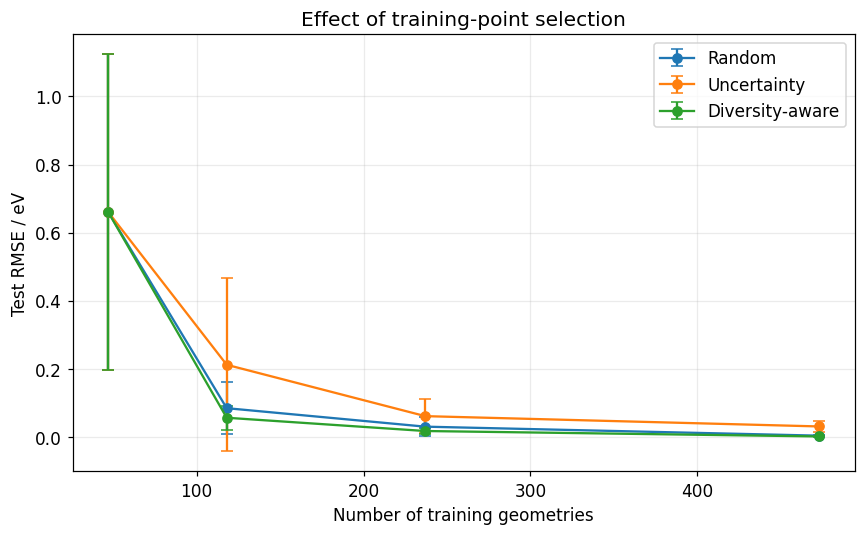

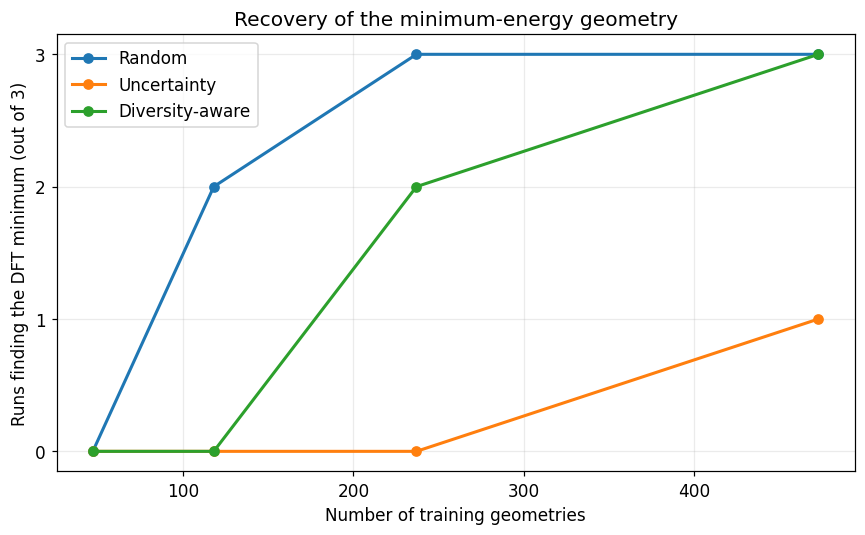

In [21]:
summary = (results.groupby(["method", "n_train"])
           .agg(mean_rmse=("rmse_ev", "mean"),
                std_rmse=("rmse_ev", "std"),
                minima_found=("correct_minimum", "sum"))
           .reset_index())
display(summary.round(6))

fig, ax = plt.subplots(figsize=(8, 5))
for method in methods:
    part = summary[summary.method == method].sort_values("n_train")
    ax.errorbar(part.n_train, part.mean_rmse, yerr=part.std_rmse,
                marker="o", capsize=4, label=method)
ax.set(xlabel="Number of training geometries", ylabel="Test RMSE / eV",
       title="Effect of training-point selection")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Count how often each method finds the DFT minimum across the three runs.
# This matters because a small overall error does not always give the right geometry.
fig, ax = plt.subplots(figsize=(8, 5))
for method in methods:
    part = summary[summary.method == method].sort_values("n_train")
    ax.plot(part.n_train, part.minima_found, "o-", linewidth=2, label=method)
ax.set(xlabel="Number of training geometries",
       ylabel="Runs finding the DFT minimum (out of 3)",
       title="Recovery of the minimum-energy geometry",
       ylim=(-0.15, 3.15))
ax.set_yticks([0, 1, 2, 3])
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Where are the training points?

Plotting the chosen geometries should help explain why one method works better than another.


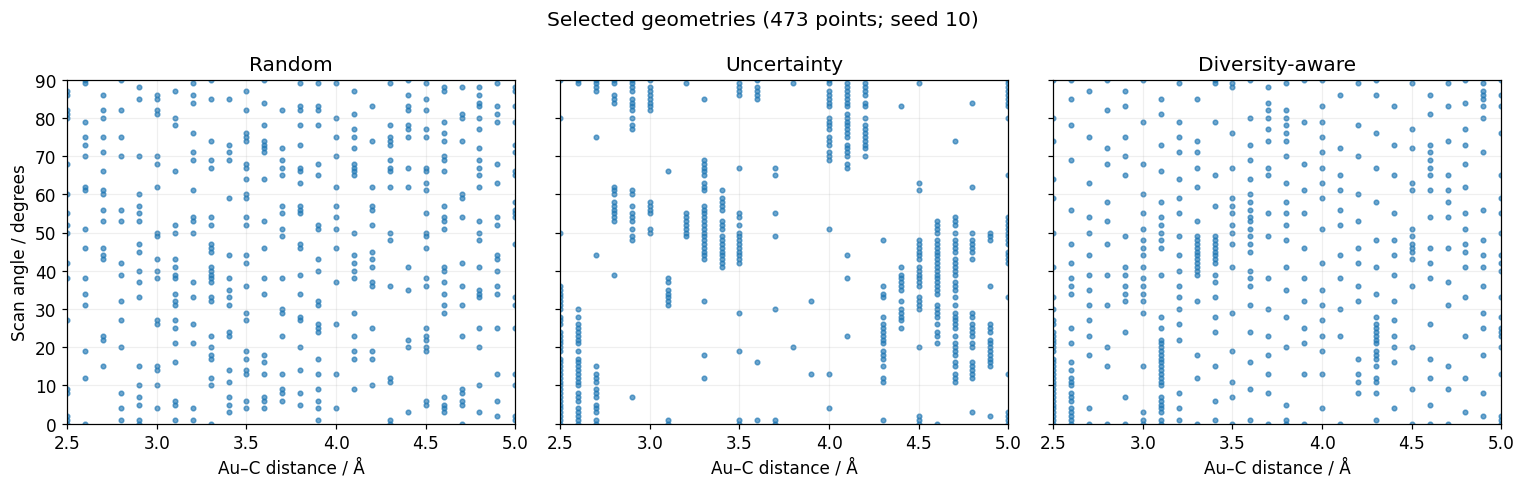

In [22]:
# Use one run to see where each method chose its training points.
seed_to_plot = 10
size_to_plot = 473
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
for ax, method in zip(axes, methods):
    idx = selected_points[(seed_to_plot, method)][size_to_plot]
    ax.scatter(X[idx, 0], X[idx, 1], s=9, alpha=0.65)
    ax.set(title=method, xlabel="Au–C distance / Å", xlim=(2.5, 5.0), ylim=(0, 90))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Scan angle / degrees")
fig.suptitle(f"Selected geometries ({size_to_plot} points; seed {seed_to_plot})")
plt.tight_layout()
plt.show()

## 9. Look more closely at the minimum

The lowest DFT point is at 3.20 Å and 23°. I compare the DFT and predicted energies across the angles at 3.20 Å to see how well the model reproduces the shape of this region.

This is not a vibrational frequency calculation, since the internal CO₂ geometry was held fixed.


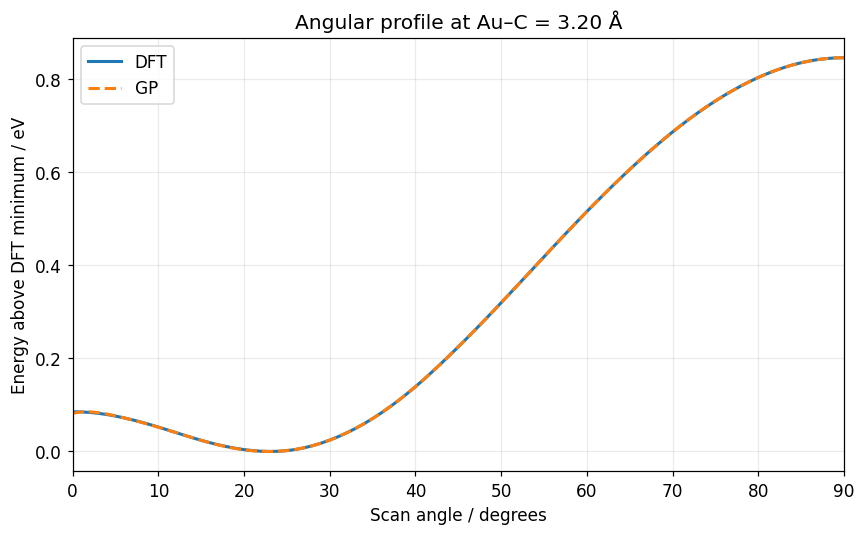

DFT minimum: 3.20 Å, 23°
GP minimum:  3.20 Å, 23°
Error at DFT minimum: -0.0756 meV


In [25]:
# Refit one final diversity-aware model using the saved selected geometries.
idx = selected_points[(10, "Diversity-aware")][473]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    final_gp, final_scale = fit_gp(idx)
pred_all = final_gp.predict(final_scale.transform(X))
compare = df.copy()
compare["gp_ev"] = pred_all

# Compare both curves at the DFT minimum distance.
profile = compare[np.isclose(compare.radius, 3.2)].sort_values("angle")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(profile.angle, profile.energy_ev, label="DFT", linewidth=2)
ax.plot(profile.angle, profile.gp_ev, "--", label="GP", linewidth=2)
ax.set(xlabel="Scan angle / degrees", ylabel="Energy above DFT minimum / eV",
       title="Angular profile at Au–C = 3.20 Å")
ax.set_xlim(0, 90)
ax.set_xticks(np.arange(0, 91, 10))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


dft_min_idx = np.argmin(y)
gp_min_idx = np.argmin(pred_all)

print(f"DFT minimum: {X[dft_min_idx, 0]:.2f} Å, {X[dft_min_idx, 1]:.0f}°")
print(f"GP minimum:  {X[gp_min_idx, 0]:.2f} Å, {X[gp_min_idx, 1]:.0f}°")
print(f"Error at DFT minimum: {1000 * (pred_all[dft_min_idx] - y[dft_min_idx]):.4f} meV")

## 10. Discussion

The Gaussian Process can reproduce much of the DFT surface from a smaller set of calculations. The interesting question is whether choosing points more carefully makes a difference.

In the repeated tests, diversity-aware selection gave lower average energy errors, while random selection sometimes found the correct minimum sooner. This suggests that fitting the whole surface accurately and finding the lowest-energy geometry are not quite the same problem.

There are limits to what I can conclude. I only tested a two-coordinate scan, the test points lie within the original grid, and three starting sets are not enough to establish a general trend. The polar plot also uses some visual adjustments that are not part of the model.

A useful next step would be to leave out specific Au–C distances during training, or focus the selection of points around the minimum.
